In [14]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt

from datasets import Dataset, load_dataset, load_from_disk
from dotenv import load_dotenv
from huggingface_hub import login

import random
from collections import Counter, defaultdict

In [ ]:


load_dotenv("../.env")

HF_TOKEN = os.environ["HF_TOKEN"]
login(token=HF_TOKEN, add_to_git_credential=False)

CACHE_DIR = Path("./deepmath-60k")
SAMPLE_SIZE = 100000

if CACHE_DIR.exists():
    questions = load_from_disk(CACHE_DIR)
else:
    def generate_questions():
        streamed = load_dataset(
            "zwhe99/DeepMath-103K",
            split="train",
            streaming=True,
            token=HF_TOKEN,
        )
        yield from streamed.take(SAMPLE_SIZE)

    questions = Dataset.from_generator(generate_questions)
    questions.save_to_disk(CACHE_DIR)

print(f"Loaded {len(questions):,} questions from {CACHE_DIR}")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Loaded 100,000 questions from deepmath-60k


In [9]:

def get_topic_counts(low,high):
    difficulty_questions = questions.filter(
    lambda row: low <= float(row["difficulty"]) <= high
)

    topic_counts = {}
    for row in difficulty_questions:
        topic = row["topic"]
        topic_counts[topic] = topic_counts.get(topic, 0) + 1

    print(f"Questions with difficulty {low}-{high}: {len(difficulty_questions):,}")
    print(f"Unique topics: {len(topic_counts)}")
    for topic, count in sorted(topic_counts.items(), key=lambda item: str(item[0])):
        print(f"{topic}: {count} questions")
        
get_topic_counts(5.0, 8.0)        


Filter: 100%|██████████| 100000/100000 [00:05<00:00, 19445.41 examples/s]


Questions with difficulty 5.0-8.0: 82,187
Unique topics: 81
Mathematics -> Algebra -> Abstract Algebra -> Category Theory: 8 questions
Mathematics -> Algebra -> Abstract Algebra -> Field Theory: 2200 questions
Mathematics -> Algebra -> Abstract Algebra -> Group Theory: 3193 questions
Mathematics -> Algebra -> Abstract Algebra -> Lie Algebras: 22 questions
Mathematics -> Algebra -> Abstract Algebra -> Other: 1055 questions
Mathematics -> Algebra -> Abstract Algebra -> Ring Theory: 1596 questions
Mathematics -> Algebra -> Algebra -> Algebraic Expressions: 626 questions
Mathematics -> Algebra -> Algebra -> Equations and Inequalities: 2048 questions
Mathematics -> Algebra -> Algebra -> Polynomial Operations: 2498 questions
Mathematics -> Algebra -> Intermediate Algebra -> Complex Numbers: 1280 questions
Mathematics -> Algebra -> Intermediate Algebra -> Exponential Functions: 1451 questions
Mathematics -> Algebra -> Intermediate Algebra -> Logarithmic Functions: 420 questions
Mathematics ->

In [10]:
difficulty_questions = questions.filter(
    lambda row: 5.0 <= float(row["difficulty"]) < 7.0
)

get_topic_counts(5.0, 6.5)

Filter: 100%|██████████| 100000/100000 [00:04<00:00, 21476.08 examples/s]


Questions with difficulty 5.0-6.5: 55,194
Unique topics: 80
Mathematics -> Algebra -> Abstract Algebra -> Category Theory: 3 questions
Mathematics -> Algebra -> Abstract Algebra -> Field Theory: 930 questions
Mathematics -> Algebra -> Abstract Algebra -> Group Theory: 1856 questions
Mathematics -> Algebra -> Abstract Algebra -> Lie Algebras: 6 questions
Mathematics -> Algebra -> Abstract Algebra -> Other: 333 questions
Mathematics -> Algebra -> Abstract Algebra -> Ring Theory: 609 questions
Mathematics -> Algebra -> Algebra -> Algebraic Expressions: 517 questions
Mathematics -> Algebra -> Algebra -> Equations and Inequalities: 1768 questions
Mathematics -> Algebra -> Algebra -> Polynomial Operations: 1922 questions
Mathematics -> Algebra -> Intermediate Algebra -> Complex Numbers: 969 questions
Mathematics -> Algebra -> Intermediate Algebra -> Exponential Functions: 1094 questions
Mathematics -> Algebra -> Intermediate Algebra -> Logarithmic Functions: 355 questions
Mathematics -> Alge

In [11]:


random.seed(42)
BROAD_PREFIXES = {
    "Algebra": (
        "Mathematics -> Algebra -> Algebra ->",
        "Mathematics -> Algebra -> Intermediate Algebra ->",
        "Mathematics -> Algebra -> Linear Algebra ->",
        "Mathematics -> Algebra -> Other",
    ),
    "Calculus": ("Mathematics -> Calculus ->",),
    "Number Theory": ("Mathematics -> Number Theory ->",),
    "Discrete Mathematics / Combinatorics": (
        "Mathematics -> Discrete Mathematics ->",
    ),
}

def broad_topic(topic):
    for broad, prefixes in BROAD_PREFIXES.items():
        if any(topic.startswith(prefix) for prefix in prefixes):
            return broad
    return None

def difficulty_bucket(difficulty):
    difficulty = float(difficulty)
    if abs(difficulty * 2 - round(difficulty * 2)) > 1e-9:
        return None
    if 5.0 <= difficulty < 7.0:
        return "5.0-6.5"
    if 7.0 <= difficulty <= 8.0:
        return "7.0-8.0"
    return None

# Count available problems in each broad-topic/difficulty stratum.
observed_difficulties = set()
invalid_increment = set()
invalid_range = set()
availability = Counter()
reservoirs = defaultdict(list)
seen = Counter()
for row in questions:
    difficulty = float(row["difficulty"])
    observed_difficulties.add(difficulty)
    if abs(difficulty * 2 - round(difficulty * 2)) > 1e-9:
        invalid_increment.add(difficulty)
    if not 5.0 <= difficulty <= 8.0:
        invalid_range.add(difficulty)

    broad = broad_topic(row["topic"])
    bucket = difficulty_bucket(difficulty)
    if broad is None or bucket is None:
        continue

    key = (broad, bucket)
    availability[key] += 1
    # Keep only as many random candidates as the largest requested stratum.
    seen[key] += 1
    if len(reservoirs[key]) < 1_024:
        reservoirs[key].append(row)
    else:
        replacement = random.randrange(seen[key])
        if replacement < 1_024:
            reservoirs[key][replacement] = row

train_per_topic = 1_024
test_per_topic = 256
train_total = train_per_topic * len(BROAD_PREFIXES)
test_total = test_per_topic * len(BROAD_PREFIXES)

# Use disjoint buckets: 80% difficulty 5.0-6.5 and 20% difficulty 7.0-8.0.
train_quota = {"5.0-6.5": 819, "7.0-8.0": 205}
test_quota = {"5.0-6.5": 205, "7.0-8.0": 51}

print(f"Observed difficulty values: {sorted(observed_difficulties)}")
print(f"Values not on a 0.5 increment: {sorted(invalid_increment) or 'none'}")
print(f"Values outside 5.0-8.0: {sorted(invalid_range) or 'none'}")

print("Available eligible problems:")
for broad in BROAD_PREFIXES:
    counts = {bucket: availability[(broad, bucket)] for bucket in ("5.0-6.5", "7.0-8.0")}
    print(f"{broad}: {counts}")

missing = []
for broad in BROAD_PREFIXES:
    for bucket in ("5.0-6.5", "7.0-8.0"):
        required = train_quota[bucket] + test_quota[bucket]
        if availability[(broad, bucket)] < required:
            missing.append((broad, bucket, required, availability[(broad, bucket)]))

if missing:
    print("Split is NOT feasible. Missing:")
    for item in missing:
        print(f"{item[0]} / difficulty {item[1]}: need {item[2]}, have {item[3]}")
else:
    train_rows, test_rows = [], []
    for broad in BROAD_PREFIXES:
        for bucket in ("5.0-6.5", "7.0-8.0"):
            candidates = reservoirs[(broad, bucket)]
            random.shuffle(candidates)
            train_rows.extend(candidates[:train_quota[bucket]])
            test_start = train_quota[bucket]
            test_rows.extend(candidates[test_start:test_start + test_quota[bucket]])

    random.shuffle(train_rows)
    random.shuffle(test_rows)
    train_split = Dataset.from_list(train_rows)
    test_split = Dataset.from_list(test_rows)
    print(f"Split is feasible: {len(train_split):,} train / {len(test_split):,} test")
    train_mean = sum(float(row["difficulty"]) for row in train_split) / len(train_split)
    test_mean = sum(float(row["difficulty"]) for row in test_split) / len(test_split)
    print(f"Mean difficulty: train={train_mean:.3f}, test={test_mean:.3f}")
    print("Subtopics are sampled naturally within each broad topic.")


Observed difficulty values: [-1.0, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
Values not on a 0.5 increment: none
Values outside 5.0-8.0: [-1.0, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 8.5, 9.0, 9.5, 10.0]
Available eligible problems:
Algebra: {'5.0-6.5': 12306, '7.0-8.0': 4141}
Calculus: {'5.0-6.5': 16133, '7.0-8.0': 9441}
Number Theory: {'5.0-6.5': 3293, '7.0-8.0': 1253}
Discrete Mathematics / Combinatorics: {'5.0-6.5': 2933, '7.0-8.0': 1550}
Split is feasible: 4,096 train / 1,024 test
Mean difficulty: train=6.030, test=6.039
Subtopics are sampled naturally within each broad topic.


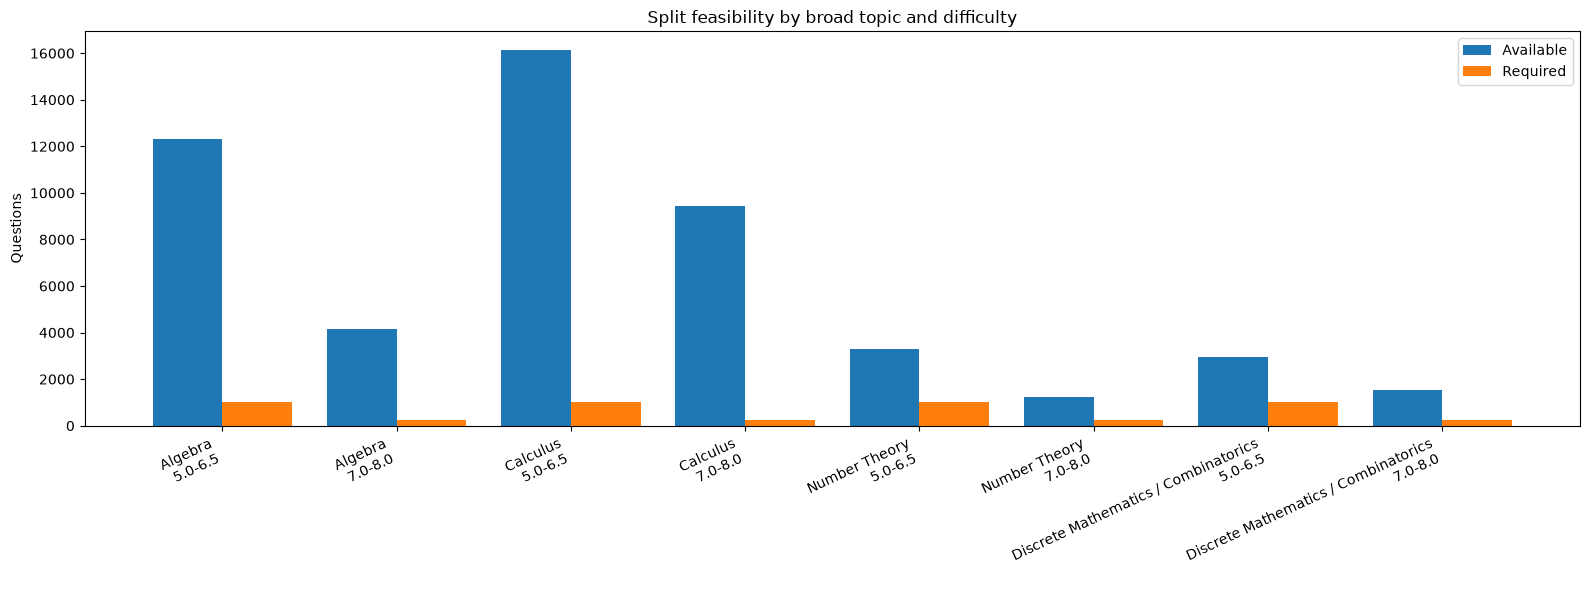

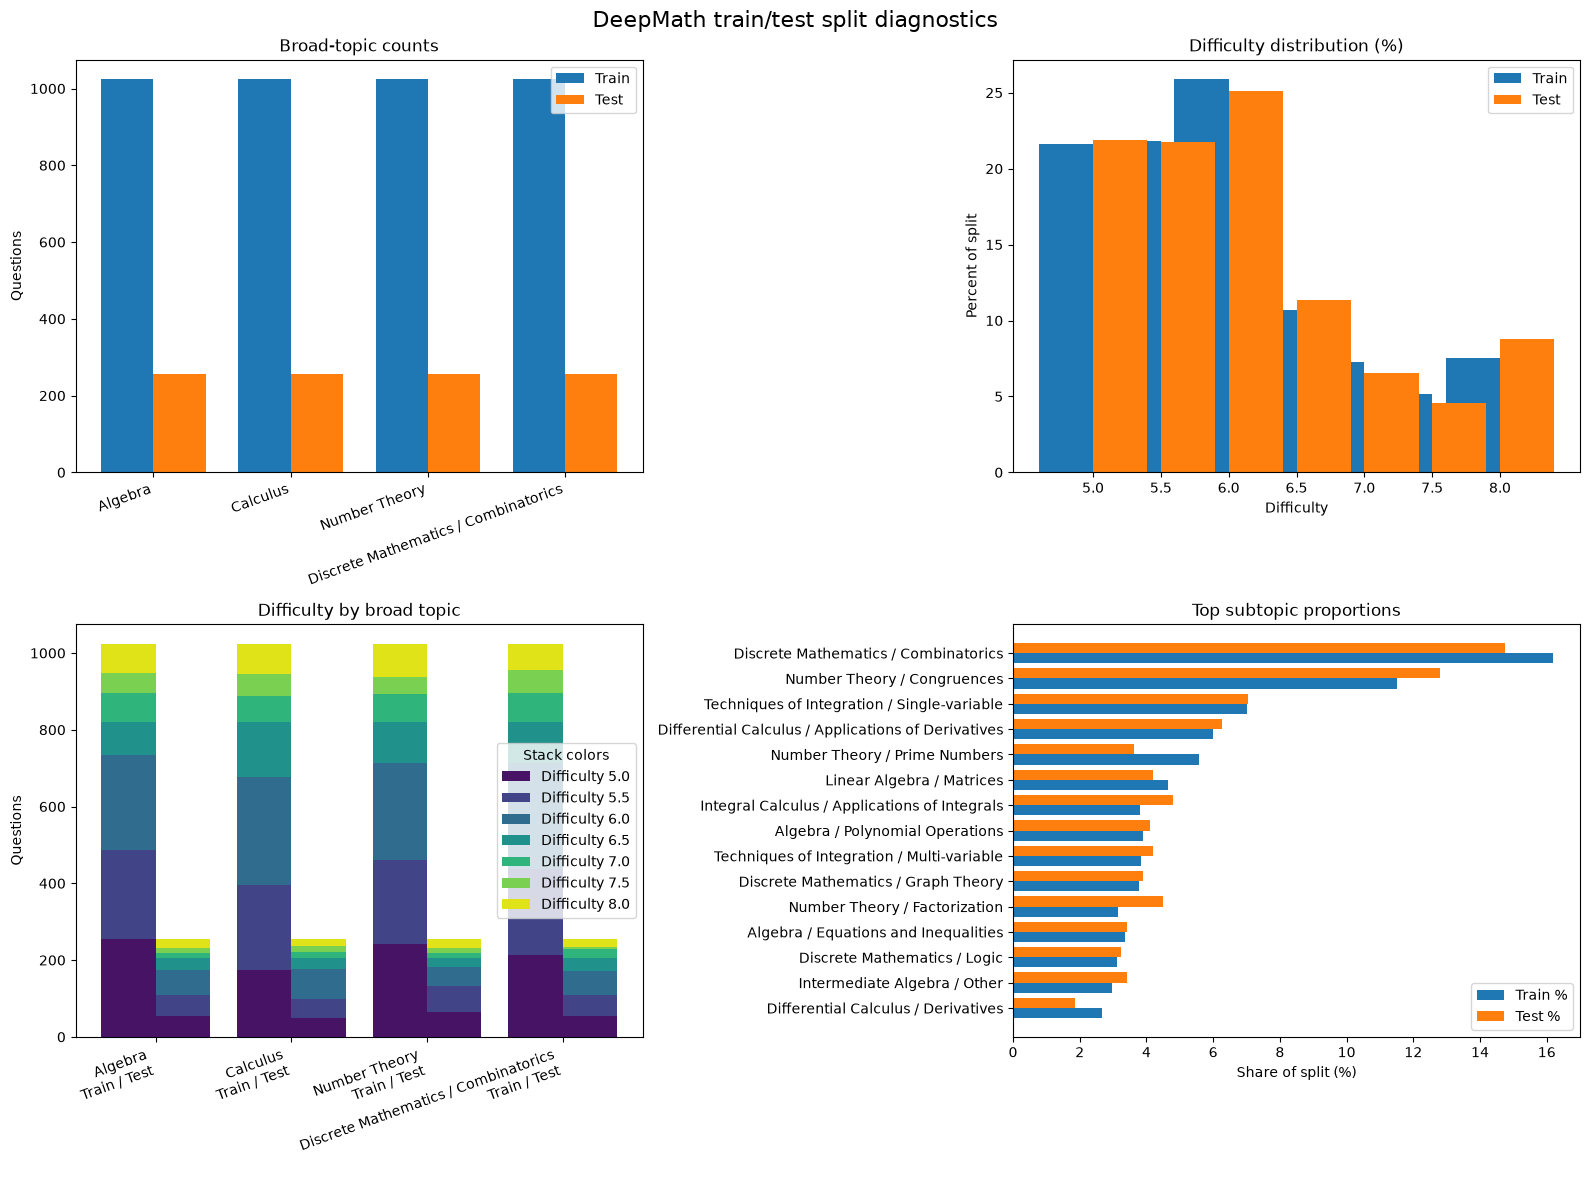

In [12]:
# Feasibility: every available bar should reach the required bar.
availability_labels = []
available_values = []
required_values = []
for broad in BROAD_PREFIXES:
    for bucket in ("5.0-6.5", "7.0-8.0"):
        availability_labels.append(f"{broad}\n{bucket}")
        available_values.append(availability[(broad, bucket)])
        required_values.append(train_quota[bucket] + test_quota[bucket])

x = range(len(availability_labels))
plt.figure(figsize=(16, 6))
plt.bar([i - 0.2 for i in x], available_values, 0.4, label="Available")
plt.bar([i + 0.2 for i in x], required_values, 0.4, label="Required")
plt.title("Split feasibility by broad topic and difficulty")
plt.ylabel("Questions")
plt.xticks(list(x), availability_labels, rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

if not missing:
    broad_order = list(BROAD_PREFIXES)
    difficulty_order = [5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0]

    def value_counts(dataset, value_fn):
        counts = Counter()
        for row in dataset:
            counts[value_fn(row)] += 1
        return counts

    train_broad = value_counts(train_split, lambda row: broad_topic(row["topic"]))
    test_broad = value_counts(test_split, lambda row: broad_topic(row["topic"]))
    train_difficulty = value_counts(train_split, lambda row: float(row["difficulty"]))
    test_difficulty = value_counts(test_split, lambda row: float(row["difficulty"]))

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # 1. The requested broad-topic allocation.
    ax = axes[0, 0]
    x = range(len(broad_order))
    width = 0.38
    ax.bar([i - width / 2 for i in x], [train_broad[t] for t in broad_order], width, label="Train")
    ax.bar([i + width / 2 for i in x], [test_broad[t] for t in broad_order], width, label="Test")
    ax.set_title("Broad-topic counts")
    ax.set_ylabel("Questions")
    ax.set_xticks(list(x), broad_order, rotation=20, ha="right")
    ax.legend()

    # 2. Overall difficulty comparison.
    ax = axes[0, 1]
    train_difficulty_pct = [100 * train_difficulty[d] / len(train_split) for d in difficulty_order]
    test_difficulty_pct = [100 * test_difficulty[d] / len(test_split) for d in difficulty_order]
    ax.bar([d - 0.2 for d in difficulty_order], train_difficulty_pct, 0.4, label="Train")
    ax.bar([d + 0.2 for d in difficulty_order], test_difficulty_pct, 0.4, label="Test")
    ax.set_title("Difficulty distribution (%)")
    ax.set_xlabel("Difficulty")
    ax.set_ylabel("Percent of split")
    ax.set_xticks(difficulty_order)
    ax.legend()

    # 3. Difficulty composition within each broad topic.
    ax = axes[1, 0]
    train_matrix = [[sum(1 for row in train_split if broad_topic(row["topic"]) == t and float(row["difficulty"]) == d) for d in difficulty_order] for t in broad_order]
    test_matrix = [[sum(1 for row in test_split if broad_topic(row["topic"]) == t and float(row["difficulty"]) == d) for d in difficulty_order] for t in broad_order]
    bottom_train = [0] * len(broad_order)
    bottom_test = [0] * len(broad_order)
    colors = plt.cm.viridis([0.05, 0.2, 0.35, 0.5, 0.65, 0.8, 0.95])
    for i, difficulty in enumerate(difficulty_order):
        train_values = [row[i] for row in train_matrix]
        test_values = [row[i] for row in test_matrix]
        ax.bar([j - 0.2 for j in x], train_values, 0.4, bottom=bottom_train, color=colors[i], label=f"Difficulty {difficulty}")
        ax.bar([j + 0.2 for j in x], test_values, 0.4, bottom=bottom_test, color=colors[i])
        bottom_train = [a + b for a, b in zip(bottom_train, train_values)]
        bottom_test = [a + b for a, b in zip(bottom_test, test_values)]
    ax.set_title("Difficulty by broad topic")
    ax.set_ylabel("Questions")
    ax.set_xticks(list(x), [f"{t}\nTrain / Test" for t in broad_order], rotation=20, ha="right")
    ax.legend(title="Stack colors")

    # 4. Top subtopics by combined frequency; proportions should be similar.
    train_subtopics = value_counts(train_split, lambda row: row["topic"])
    test_subtopics = value_counts(test_split, lambda row: row["topic"])
    combined = train_subtopics + test_subtopics
    top_subtopics = [topic for topic, _ in combined.most_common(15)][::-1]
    labels = [topic.split(" -> ")[-2:] for topic in top_subtopics]
    labels = [" / ".join(parts) for parts in labels]
    train_pct = [100 * train_subtopics[t] / len(train_split) for t in top_subtopics]
    test_pct = [100 * test_subtopics[t] / len(test_split) for t in top_subtopics]
    ax = axes[1, 1]
    y = range(len(top_subtopics))
    ax.barh([i - 0.2 for i in y], train_pct, 0.4, label="Train %")
    ax.barh([i + 0.2 for i in y], test_pct, 0.4, label="Test %")
    ax.set_title("Top subtopic proportions")
    ax.set_xlabel("Share of split (%)")
    ax.set_yticks(list(y), labels)
    ax.legend()

    plt.suptitle("DeepMath train/test split diagnostics", fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No split visualizations generated because the requested split is infeasible.")


In [15]:
PILOT_PATH = Path("../inputs/deepmath-pilot-50.json")
PILOT_QUOTA = {
    "Algebra": {"5.0-6.5": 10, "7.0-8.0": 3},
    "Calculus": {"5.0-6.5": 10, "7.0-8.0": 3},
    "Number Theory": {"5.0-6.5": 10, "7.0-8.0": 2},
    "Discrete Mathematics / Combinatorics": {"5.0-6.5": 10, "7.0-8.0": 2},
}

if PILOT_PATH.exists():
    pilot_data = json.loads(PILOT_PATH.read_text(encoding="utf-8"))
    pilot_rows = pilot_data["problems"]
    print(f"Loaded existing pilot set from {PILOT_PATH}")
else:
    rng = random.Random(42)
    candidates = defaultdict(list)
    seen = Counter()

    for row in questions:
        broad = broad_topic(row["topic"])
        bucket = difficulty_bucket(row["difficulty"])
        quota = PILOT_QUOTA.get(broad, {}).get(bucket, 0)
        if quota == 0:
            continue

        key = (broad, bucket)
        seen[key] += 1
        if len(candidates[key]) < quota:
            candidates[key].append(row)
        else:
            replacement = rng.randrange(seen[key])
            if replacement < quota:
                candidates[key][replacement] = row

    missing = []
    for broad, bucket_quotas in PILOT_QUOTA.items():
        for bucket, quota in bucket_quotas.items():
            available = seen[(broad, bucket)]
            if available < quota:
                missing.append((broad, bucket, quota, available))

    if missing:
        raise ValueError(f"Pilot split is infeasible: {missing}")

    pilot_rows = []
    for broad, bucket_quotas in PILOT_QUOTA.items():
        for bucket, quota in bucket_quotas.items():
            selected = candidates[(broad, bucket)]
            rng.shuffle(selected)
            pilot_rows.extend(selected[:quota])
    rng.shuffle(pilot_rows)

    pilot_data = {
        "dataset": "zwhe99/DeepMath-103K",
        "sample_size": len(pilot_rows),
        "seed": 42,
        "difficulty_buckets": {
            "lower": "5.0-6.5",
            "upper": "7.0-8.0",
        },
        "problems": pilot_rows,
    }
    PILOT_PATH.write_text(json.dumps(pilot_data, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Saved pilot set to {PILOT_PATH}")

pilot_topic_counts = Counter(broad_topic(row["topic"]) for row in pilot_rows)
pilot_bucket_counts = Counter(difficulty_bucket(row["difficulty"]) for row in pilot_rows)
print(f"Pilot size: {len(pilot_rows)}")
print(f"Broad-topic counts: {dict(pilot_topic_counts)}")
print(f"Difficulty-bucket counts: {dict(pilot_bucket_counts)}")


Saved pilot set to deepmath-pilot-50.json
Pilot size: 50
Broad-topic counts: {'Algebra': 13, 'Discrete Mathematics / Combinatorics': 12, 'Number Theory': 12, 'Calculus': 13}
Difficulty-bucket counts: {'5.0-6.5': 40, '7.0-8.0': 10}
